In [1]:
import os
import glob
import numpy as np
import scipy.io
import matplotlib.pyplot as plt

from scipy.stats import kurtosis, skew
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler


# === CWRU Bearing Dataset Overview ===

Dataset Name       : Case Western Reserve University (CWRU) Bearing Dataset
Signal Type        : Vibration (Drive End)
Sampling Frequency : 12 kHz
Sensor Location    : Drive End (DE)
Data Format        : MATLAB (.mat)

Fault Types Included:
1. Normal (Healthy Bearing)
2. Ball Fault
3. Inner Race Fault
4. Outer Race Fault

Feature Types Used:
- Time Domain Features
- Frequency Domain Features (FFT-based)

Model Usage:
- One-Class SVM (Anomaly Detection)

In [12]:
from collections import defaultdict

def count_files_by_category(dataset_path):
    file_counts = defaultdict(int)
    
    search_path = os.path.join(dataset_path, "**", "*.mat")
    files = glob.glob(search_path, recursive=True)

    for f in files:
        if "Normal" in f:
            file_counts["Normal"] += 1
        elif "\\B\\" in f or "/B/" in f:
            file_counts["Ball Fault"] += 1
        elif "\\IR\\" in f or "/IR/" in f:
            file_counts["Inner Race Fault"] += 1
        elif "\\OR\\" in f or "/OR/" in f:
            file_counts["Outer Race Fault"] += 1
        else:
            file_counts["Other"] += 1

    return file_counts

file_counts = count_files_by_category(dataset_path)

print("=== Number of Files per Category ===")
for k, v in file_counts.items():
    print(f"{k}: {v}")


=== Number of Files per Category ===
Ball Fault: 40
Inner Race Fault: 40
Outer Race Fault: 77
Normal: 4


# === Feature Engineering Details ===

Window Size        : 1024 samples
Window Type        : Non-overlapping
Number of Features : 8

Time Domain Features:
1. Mean
2. Standard Deviation
3. RMS
4. Kurtosis
5. Skewness
6. Crest Factor

Frequency Domain Features:
7. Peak Frequency
8. Spectral Centroid

In [2]:
def extract_features(signal, fs=12000, window_size=1024):
    """
    Extracts combined time-domain and frequency-domain features
    from vibration signal windows.
    """
    num_windows = len(signal) // window_size
    features = []

    for i in range(num_windows):
        window = signal[i*window_size : (i+1)*window_size]

        # ---- Time Domain Features ----
        mean_val = np.mean(window)
        std_val = np.std(window)
        rms_val = np.sqrt(np.mean(window**2))
        peak_val = np.max(np.abs(window))
        kurt_val = kurtosis(window)
        skew_val = skew(window)
        crest_factor = peak_val / (rms_val + 1e-6)

        # ---- Frequency Domain Features (FFT) ----
        fft_vals = np.abs(np.fft.rfft(window))
        fft_freqs = np.fft.rfftfreq(window_size, 1/fs)

        peak_freq = fft_freqs[np.argmax(fft_vals)]
        spec_centroid = np.sum(fft_freqs * fft_vals) / (np.sum(fft_vals) + 1e-6)

        features.append([
            mean_val, std_val, rms_val,
            kurt_val, skew_val, crest_factor,
            peak_freq, spec_centroid
        ])

    return np.array(features)


In [3]:
def load_data(dataset_path):
    """
    Leakage-free loading:
    - Normal data split by TIME (80% train, 20% test)
    - Fault data used ONLY for testing
    """
    normal_train = []
    normal_test = []
    anomaly_data = []

    search_path = os.path.join(dataset_path, "**", "*.mat")
    all_files = glob.glob(search_path, recursive=True)

    print(f"Processing {len(all_files)} files...")

    for filepath in all_files:
        try:
            mat = scipy.io.loadmat(filepath)
            key = next((k for k in mat.keys() if "DE_time" in k), None)
            if key is None:
                continue

            signal = mat[key].flatten()

            if "Normal" in filepath:
                split = int(0.8 * len(signal))

                train_signal = signal[:split]
                test_signal = signal[split:]

                normal_train.append(extract_features(train_signal))
                normal_test.append(extract_features(test_signal))

            else:
                anomaly_data.append(extract_features(signal))

        except Exception as e:
            print(f"Error reading {filepath}: {e}")

    X_train = np.vstack(normal_train)
    X_test_normal = np.vstack(normal_test)
    X_test_anomaly = np.vstack(anomaly_data)

    return X_train, X_test_normal, X_test_anomaly


# === Processed Dataset Sizes ===
Training Samples (Normal): 1325
Testing Samples (Normal - Unseen Time): 329
Testing Samples (Anomaly): 33414

Feature Vector Size: 8

In [4]:
dataset_path = r"./CWRU-dataset"

X_train, X_test_normal, X_test_anomaly = load_data(dataset_path)

print("Training (Normal):", X_train.shape)
print("Test Normal (Unseen Time):", X_test_normal.shape)
print("Test Anomaly:", X_test_anomaly.shape)


Processing 161 files...
Training (Normal): (1325, 8)
Test Normal (Unseen Time): (329, 8)
Test Anomaly: (33414, 8)


In [6]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_normal_scaled = scaler.transform(X_test_normal)
X_test_anomaly_scaled = scaler.transform(X_test_anomaly)


In [7]:
model = OneClassSVM(
    kernel="rbf",
    nu=0.05,
    gamma="scale"
)

model.fit(X_train_scaled)


OneClassSVM(nu=0.05)

In [8]:
# 1 = Normal, -1 = Anomaly
y_pred_normal = model.predict(X_test_normal_scaled)
y_pred_anomaly = model.predict(X_test_anomaly_scaled)


In [9]:
tp = np.sum(y_pred_anomaly == -1)  # Fault detected
fn = np.sum(y_pred_anomaly == 1)   # Fault missed

tn = np.sum(y_pred_normal == 1)    # Normal correct
fp = np.sum(y_pred_normal == -1)   # False alarm

print("\n--- Leakage-Free Evaluation ---")
print(f"Fault Detection Rate (Recall): {tp / (tp + fn):.2%}")
print(f"False Alarm Rate: {fp / (fp + tn):.2%}")



--- Leakage-Free Evaluation ---
Fault Detection Rate (Recall): 100.00%
False Alarm Rate: 14.59%


In [10]:
print("\nConfusion Matrix:")
print(f"[[{tp}  (Fault Detected), {fn}  (Fault Missed)]")
print(f" [{fp}  (False Alarm),   {tn}  (Normal Correct)]]")



Confusion Matrix:
[[33413  (Fault Detected), 1  (Fault Missed)]
 [48  (False Alarm),   281  (Normal Correct)]]


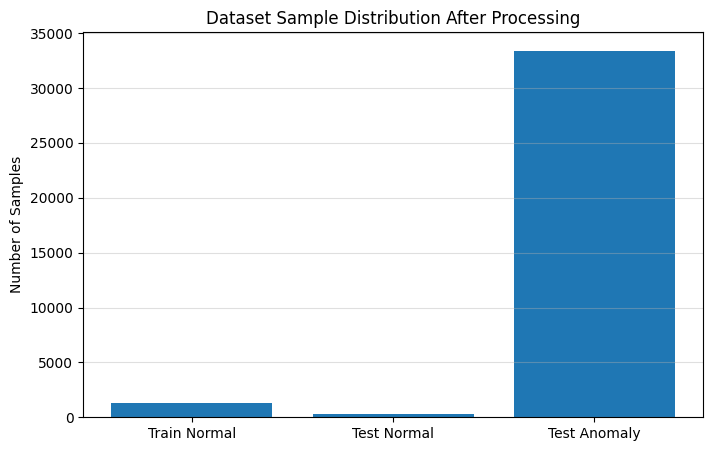

In [15]:
import matplotlib.pyplot as plt

labels = ["Train Normal", "Test Normal", "Test Anomaly"]
sizes = [
    X_train.shape[0],
    X_test_normal.shape[0],
    X_test_anomaly.shape[0]
]

plt.figure(figsize=(8,5))
plt.bar(labels, sizes)
plt.title("Dataset Sample Distribution After Processing")
plt.ylabel("Number of Samples")
plt.grid(axis="y", alpha=0.4)
plt.show()


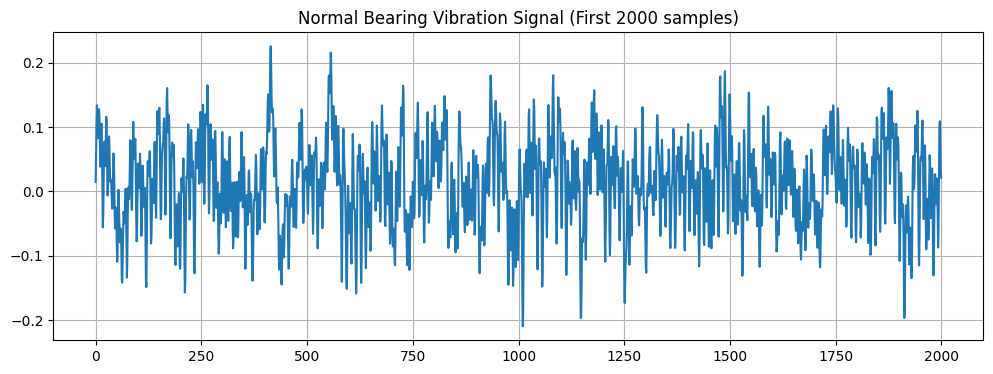

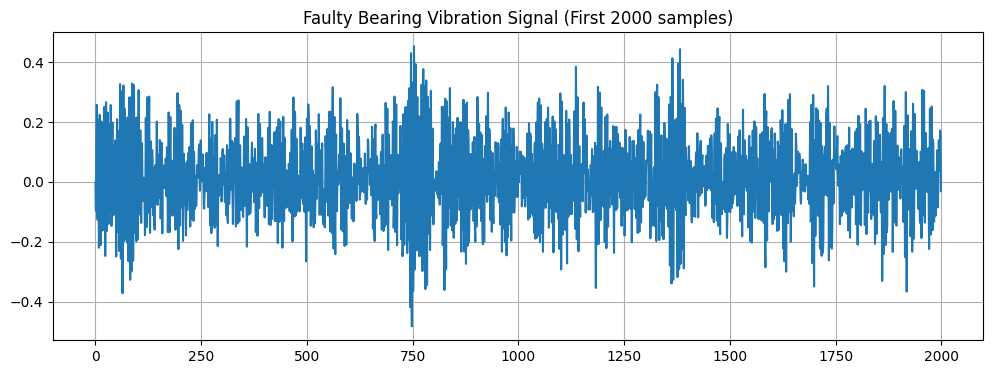

In [16]:
# Pick one normal and one fault signal for visualization
normal_file = next(f for f in glob.glob(os.path.join(dataset_path, "**", "*.mat"), recursive=True) if "Normal" in f)
fault_file = next(f for f in glob.glob(os.path.join(dataset_path, "**", "*.mat"), recursive=True) if "Fault" in f or "IR" in f or "OR" in f)

def load_signal(filepath):
    mat = scipy.io.loadmat(filepath)
    key = next(k for k in mat.keys() if "DE_time" in k)
    return mat[key].flatten()

normal_signal = load_signal(normal_file)
fault_signal = load_signal(fault_file)

plt.figure(figsize=(12,4))
plt.plot(normal_signal[:2000])
plt.title("Normal Bearing Vibration Signal (First 2000 samples)")
plt.grid(True)
plt.show()

plt.figure(figsize=(12,4))
plt.plot(fault_signal[:2000])
plt.title("Faulty Bearing Vibration Signal (First 2000 samples)")
plt.grid(True)
plt.show()


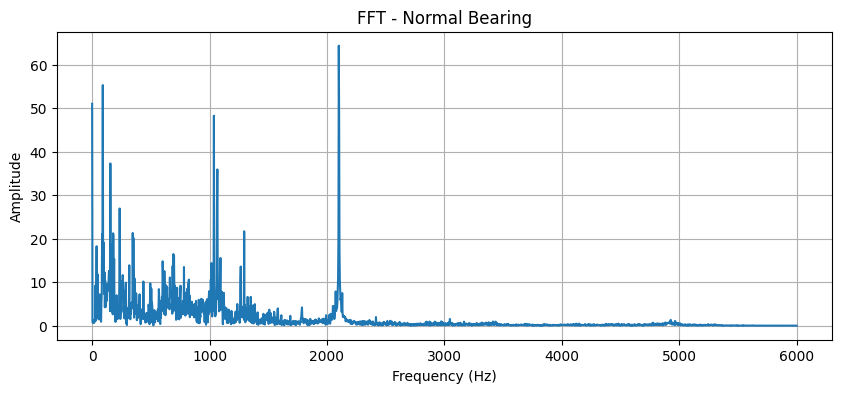

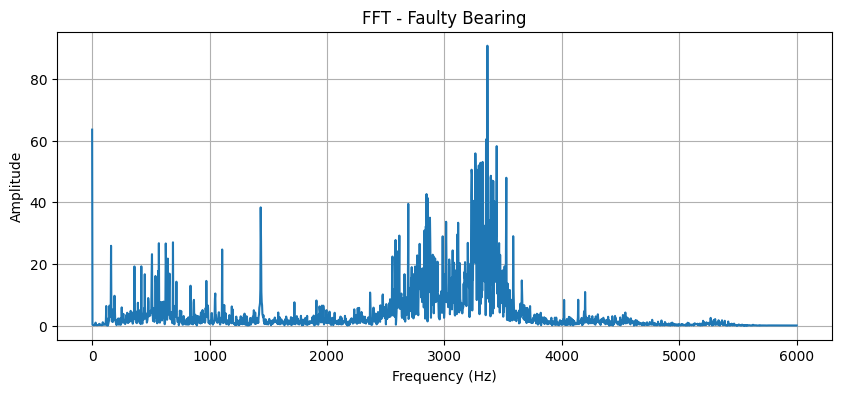

In [17]:
def plot_fft(signal, fs=12000, title="FFT"):
    fft_vals = np.abs(np.fft.rfft(signal[:4096]))
    freqs = np.fft.rfftfreq(4096, 1/fs)

    plt.figure(figsize=(10,4))
    plt.plot(freqs, fft_vals)
    plt.title(title)
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Amplitude")
    plt.grid(True)
    plt.show()

plot_fft(normal_signal, title="FFT - Normal Bearing")
plot_fft(fault_signal, title="FFT - Faulty Bearing")


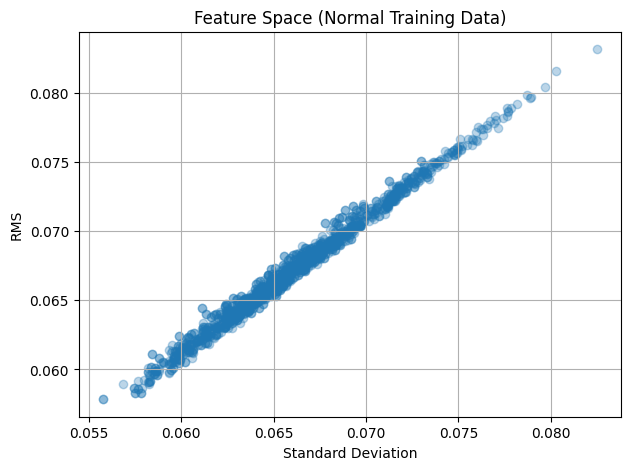

In [20]:
plt.figure(figsize=(7,5))
plt.scatter(X_train[:,1], X_train[:,2], alpha=0.3)
plt.xlabel("Standard Deviation")
plt.ylabel("RMS")
plt.title("Feature Space (Normal Training Data)")
plt.grid(True)
plt.show()


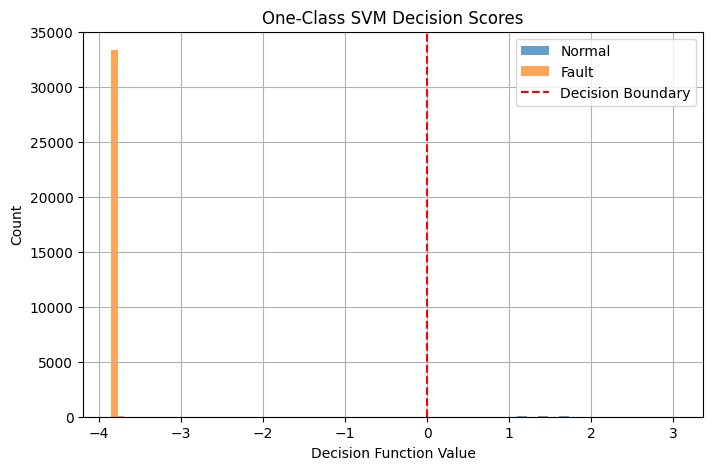

In [21]:
import numpy as np

normal_scores = model.decision_function(X_test_normal_scaled)
fault_scores = model.decision_function(X_test_anomaly_scaled)

plt.figure(figsize=(8,5))
plt.hist(normal_scores, bins=50, alpha=0.7, label="Normal")
plt.hist(fault_scores, bins=50, alpha=0.7, label="Fault")
plt.axvline(0, color="red", linestyle="--", label="Decision Boundary")
plt.title("One-Class SVM Decision Scores")
plt.xlabel("Decision Function Value")
plt.ylabel("Count")
plt.legend()
plt.grid(True)
plt.show()
